In [1]:
from typing_extensions import TypedDict

class MyState(TypedDict):
    message: str
    a: str
    b: str

In [2]:
def function_1(state: MyState) -> MyState:
    print("Function 1 called with input:", state)
    
    return {'a': state['message'] + " world"}


def function_2(state: MyState) -> MyState:
    print("Function 2 called with input:", state)
    return {'b': state['a'] + "!"}

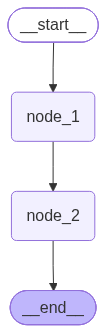

In [5]:
from langgraph.graph import StateGraph
from IPython.display import display, Image

workflow = StateGraph(MyState)
workflow.add_node("node_1", function_1)
workflow.add_node("node_2", function_2)
workflow.add_edge("node_1", "node_2")
workflow.set_entry_point("node_1")
workflow.set_finish_point("node_2")

app = workflow.compile()
app

In [6]:
app.invoke({"message": "Hello "})

Function 1 called with input: {'message': 'Hello '}
Function 2 called with input: {'message': 'Hello ', 'a': 'Hello  world'}


{'message': 'Hello ', 'a': 'Hello  world', 'b': 'Hello  world!'}

In [7]:
for output in app.stream({"message": "Hello "}):
    for key, value in output.items():
        print(f"{key}: {value}")

Function 1 called with input: {'message': 'Hello '}
node_1: {'a': 'Hello  world'}
Function 2 called with input: {'message': 'Hello ', 'a': 'Hello  world'}
node_2: {'b': 'Hello  world!'}


In [9]:
from dotenv import load_dotenv
load_dotenv()

True

In [34]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(model="gpt-4o-mini")

In [12]:
class MyState(TypedDict):
    messages: list

def function_1(state):
    response = model.invoke(state['messages'])
    
    return {"messages": [response]}

def function_2(state):
    print("Function 2 called with input:", state)
    return state

In [13]:
from langchain_core.messages import AIMessage, HumanMessage

workflow = StateGraph(MyState)
workflow.add_node("node_1", function_1)
workflow.add_node("node_2", function_2)
workflow.add_edge("node_1", "node_2")
workflow.set_entry_point("node_1")
workflow.set_finish_point("node_2")
app = workflow.compile()

app.invoke({"messages": [HumanMessage(content="Hello")]})

Function 2 called with input: {'messages': [AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9f01cdda3d', 'id': 'chatcmpl-EgP4L0ZQVHZ8TvFdhMoYtIQikRo5x', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a550-0ad4-7092-a39b-3a7eb472e926-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_detail

{'messages': [AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_9f01cdda3d', 'id': 'chatcmpl-EgP4L0ZQVHZ8TvFdhMoYtIQikRo5x', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1a550-0ad4-7092-a39b-3a7eb472e926-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 

In [14]:
from langchain_community.utilities import OpenWeatherMapAPIWrapper
import os
weather = OpenWeatherMapAPIWrapper()

C:\Users\Training\AppData\Local\Temp\ipykernel_37756\3622699175.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import OpenWeatherMapAPIWrapper


In [15]:
weather_data = weather.run("Bangalore")
print(weather_data)

In Bangalore, the current weather is as follows:
Detailed status: broken clouds
Wind speed: 2.77 m/s, direction: 329°
Humidity: 60%
Temperature: 
  - Current: 28.73°C
  - High: 28.73°C
  - Low: 28.73°C
  - Feels like: 30.58°C
Rain: {}
Heat index: None
Cloud cover: 56%


In [17]:
class MyState(TypedDict):
    query: str
    city: str
    response: str

def function_1(state):
    prompt = "Your task is to provide only city name based on the query. " \
             "Just return the city name without any additional text. Following is the query: " + state['query']

    response = model.invoke(prompt)
    
    return {"city": response.content}

def function_2(state):
    response = weather.run(state['city'])
    return {"response": response}

def function_3(state):
    agent2_query = """Your task is to provide info concisely based on the
             user query and the available information from the internet.
            Following is the user query: """ + state['query'] + " Available information: " + state['response']
    response = model.invoke(agent2_query)
    return {"response": response.content}

In [18]:
workflow = StateGraph(MyState)
workflow.add_node("node_1", function_1)
workflow.add_node("node_2", function_2)
workflow.add_node("node_3", function_3)
workflow.add_edge("node_1", "node_2")
workflow.add_edge("node_2", "node_3")
workflow.set_entry_point("node_1")
workflow.set_finish_point("node_3")
app = workflow.compile()

app.invoke({"query": "What is the windspeed in Bangalore today?"})

{'query': 'What is the windspeed in Bangalore today?',
 'city': 'Bangalore',
 'response': 'The wind speed in Bangalore today is 2.77 m/s, coming from the northwest (329°).'}

In [19]:
from typing import TypedDict, Annotated, Sequence
import operator
from langchain_core.messages import BaseMessage

class AgentState(TypedDict):
    messages: Annotated[list, operator.add]

In [21]:
def function_1(state):
    messages = state['messages']
    user_input = messages[-1]
    complete_query = "Your task is to provide only the city name based on the user query. " \
                     "Nothing more, just the city name mentioned. Following is the user query: " + user_input
    response = model.invoke(complete_query)
  
    return {"messages": [response.content]}

def function_2(state):
    messages = state['messages']
    agent_response = messages[-1]
    weather = OpenWeatherMapAPIWrapper()
    weather_data = weather.run(agent_response)
    return {"messages": [weather_data]}

def function_3(state):
    messages = state['messages']
    user_input = messages[0]
    available_info = messages[-1]
    agent2_query = """Your task is to provide info concisely based on the
             user query and the available information from the internet.
            Following is the user query: """ + user_input + " Available information: " + available_info
    response = model.invoke(agent2_query)
    return {"messages": [response.content]}

In [22]:
workflow = StateGraph(AgentState)
workflow.add_node("node_1", function_1)
workflow.add_node("node_2", function_2)
workflow.add_node("node_3", function_3)
workflow.add_edge("node_1", "node_2")  
workflow.add_edge("node_2", "node_3")
workflow.set_entry_point("node_1")
workflow.set_finish_point("node_3")
app = workflow.compile()

app.invoke({"messages": ["What is the temperature in Bangalore today?"]})

{'messages': ['What is the temperature in Bangalore today?',
  'Bangalore',
  'In Bangalore, the current weather is as follows:\nDetailed status: broken clouds\nWind speed: 2.77 m/s, direction: 329°\nHumidity: 60%\nTemperature: \n  - Current: 28.73°C\n  - High: 28.73°C\n  - Low: 28.73°C\n  - Feels like: 30.58°C\nRain: {}\nHeat index: None\nCloud cover: 56%',
  'The current temperature in Bangalore today is 28.73°C, with a feels-like temperature of 30.58°C.']}

In [23]:
from typing import TypedDict, Annotated, Sequence
import operator
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]
    # messages: Annotated[Sequence[BaseMessage], operator.add]

In [24]:
from langgraph.graph.message import add_messages
from langchain_core.messages import AIMessage, HumanMessage

# Initial state
initial_messages = [AIMessage(content="Hello! How can I assist you?", name="Model"),
                    HumanMessage(content="I'm looking for information on marine biology.", name="Siva")
                   ]

# New message to add
new_message = AIMessage(content="Sure, I can help with that. What specifically are you interested in?", name="Model")

# Test
add_messages(initial_messages, new_message)

[AIMessage(content='Hello! How can I assist you?', additional_kwargs={}, response_metadata={}, name='Model', id='8b3ba98e-7230-422b-996c-83f510a32029', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="I'm looking for information on marine biology.", additional_kwargs={}, response_metadata={}, name='Siva', id='792cf43b-b243-44bd-b539-8d8da9c395f6'),
 AIMessage(content='Sure, I can help with that. What specifically are you interested in?', additional_kwargs={}, response_metadata={}, name='Model', id='418f54da-ca42-4518-9e00-cbaeb0922cd5', tool_calls=[], invalid_tool_calls=[])]

In [25]:
# Initial state
initial_messages = [AIMessage(content="Hello! How can I assist you?", name="Model", id="1"),
                    HumanMessage(content="I'm looking for information on marine biology.", name="Siva", id="2")
                   ]

# New message to add (same ID as existing message)
new_message = HumanMessage(content="I'm looking for information on whales, specifically", name="Siva", id="2")

# Test
add_messages(initial_messages, new_message)

[AIMessage(content='Hello! How can I assist you?', additional_kwargs={}, response_metadata={}, name='Model', id='1', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="I'm looking for information on whales, specifically", additional_kwargs={}, response_metadata={}, name='Siva', id='2')]

In [26]:
from langchain_core.messages import RemoveMessage

# Message list
messages = [AIMessage("Hi.", name="Bot", id="1")]
messages.append(HumanMessage("Hi.", name="Siva", id="2"))
messages.append(AIMessage("So you said you were researching ocean mammals?", name="Bot", id="3"))
messages.append(HumanMessage("Yes, I know about whales. But what others should I learn about?", name="Siva", id="4"))

# Isolate messages to delete (all except last 2)
delete_messages = [RemoveMessage(id=m.id) for m in messages[:-2]]
print(delete_messages)

add_messages(messages, delete_messages)

[RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='1'), RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='2')]


[AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Siva', id='4')]

In [36]:
from langchain_tavily import TavilySearch
from langchain_openai import ChatOpenAI

tools = [TavilySearch(max_results=3)]

model = ChatOpenAI(temperature=0, streaming=True,  model="gpt-5.4-mini")
model = model.bind_tools(tools)

In [37]:
def function_1(state):
    messages = state['messages']

    response = model.invoke(messages)
    print("Response from function_1", response)
    return {"messages": [response]}

In [38]:
def where_to_go(state):
    messages = state['messages']
    last_message = messages[-1]
    print("Inside where to go=== ", last_message)

    if last_message.tool_calls:
        return "continue"
    else:
        return "end"

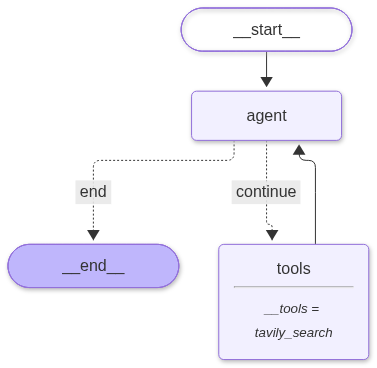

In [39]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode, tools_condition

workflow = StateGraph(state_schema=AgentState)

workflow.add_node("agent", function_1)
workflow.add_node("tools", ToolNode(tools=tools))

workflow.add_conditional_edges("agent", where_to_go, {
    "continue": "tools",
    "end": END
})

workflow.add_edge('tools', 'agent')

workflow.set_entry_point("agent")

conn = sqlite3.connect("checkpoints.sqlite", check_same_thread=False)
memory = SqliteSaver(conn)

app = workflow.compile(checkpointer=memory)

app

In [40]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "1"}}

inputs = {"messages": [HumanMessage(content="What are the latest developments in LangGraph?")]}
response = app.invoke(inputs, config)
response

Response from function_1 content='' additional_kwargs={} response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 'model_provider': 'openai'} id='lc_run--01a1a558-6f19-70df-8aac-fdac7f174589' tool_calls=[{'name': 'tavily_search', 'args': {'query': 'LangGraph latest developments release notes blog changelog 2025', 'search_depth': 'advanced', 'topic': 'general', 'time_range': 'month'}, 'id': 'call_U5JEK1nxDGrCeF6YkK0IcG8z', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 1303, 'output_tokens': 47, 'total_tokens': 1350, 'input_token_details': {'audio': 0, 'cache_read': 1152}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
Inside where to go===  content='' additional_kwargs={} response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 'model_provider': 'openai'} id='lc_run--01a1a558-6f19-70df-8aac-fdac7f174589' tool_calls=[{'name': 'tavi

{'messages': [HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='e847b159-4989-4a7b-85ce-1c3068731126'),
  HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='64d27975-15a4-48ce-bc4b-94e861d7fb6c'),
  HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='14257452-7100-4993-a28d-2da96774a7ee'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 'model_provider': 'openai'}, id='lc_run--01a1a558-6f19-70df-8aac-fdac7f174589', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'LangGraph latest developments release notes blog changelog 2025', 'search_depth': 'advanced', 'topic': 'general', 'time_range': 'month'}, 'id': 'call_U5JEK1nxDGrCeF6YkK0IcG8z', 'type': 'tool_call'}], inva

In [41]:
snapshot = app.get_state(config)
snapshot

StateSnapshot(values={'messages': [HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='e847b159-4989-4a7b-85ce-1c3068731126'), HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='64d27975-15a4-48ce-bc4b-94e861d7fb6c'), HumanMessage(content='What are the latest developments in LangGraph?', additional_kwargs={}, response_metadata={}, id='14257452-7100-4993-a28d-2da96774a7ee'), AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 'model_provider': 'openai'}, id='lc_run--01a1a558-6f19-70df-8aac-fdac7f174589', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'LangGraph latest developments release notes blog changelog 2025', 'search_depth': 'advanced', 'topic': 'general', 'time_range': 'month'}, 'id': 'call_U5JEK1nxDGrCeF6YkK0IcG8z', 'type': 'too

In [42]:
user_input = "What is java language? "
config = {"configurable": {"thread_id": "15"}}
# The config is the **second positional argument** to stream() or invoke()!
events = app.stream(
    {"messages": [("user", user_input)]}, config, stream_mode="values"
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

What is java language? 
Response from function_1 content='Java is a high-level, object-oriented programming language used to build many kinds of software, including:\n\n- web applications\n- mobile apps, especially Android\n- desktop software\n- enterprise systems\n- backend services\n- embedded systems\n\n### Key features of Java:\n- **Platform-independent**: Java code runs on many systems using the Java Virtual Machine (JVM).  \n- **Object-oriented**: It organizes code into objects and classes.  \n- **Strongly typed**: Variables have specific data types.  \n- **Secure and robust**: It includes features to help prevent many common programming errors.  \n- **Multithreaded**: It can handle multiple tasks at once.\n\n### Simple example:\n```java\npublic class Main {\n    public static void main(String[] args) {\n        System.out.println("Hello, world!");\n    }\n}\n```\n\nThis program prints `Hello, world

In [43]:

user_input = "What are today's top technology news headlines?"
config = {"configurable": {"thread_id": "16"}}
# The config is the **second positional argument** to stream() or invoke()!
events = app.stream(
    {"messages": [("user", user_input)]}, config, stream_mode="values"
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

What are today's top technology news headlines?
Response from function_1 content='' additional_kwargs={} response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 'model_provider': 'openai'} id='lc_run--01a1a559-685b-712b-9f14-5acfaececaa5' tool_calls=[{'name': 'tavily_search', 'args': {'query': 'today top technology news headlines latest', 'topic': 'news', 'search_depth': 'advanced', 'time_range': 'day'}, 'id': 'call_pZES6qSqj33RttC7zk3HqE2D', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 1276, 'output_tokens': 41, 'total_tokens': 1317, 'input_token_details': {'audio': 0, 'cache_read': 1152}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
Inside where to go===  content='' additional_kwargs={} response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-5.4-mini-2026-03-17', 'service_tier': 'default', 

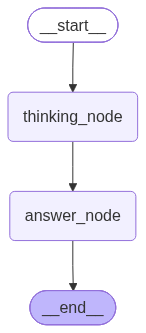

{'question': 'hi', 'answer': 'bye Siva', 'notes': '... his is name is Siva'}

In [47]:
from langgraph.graph import StateGraph, START, END

class OverallState(TypedDict):
    question: str
    answer: str
    notes: str

def thinking_node(state: OverallState):
    return {"answer": "bye", "notes": "... his is name is Siva"}

def answer_node(state: OverallState):
    return {"answer": "bye Siva"}

graph = StateGraph(OverallState)
graph.add_node("answer_node", answer_node)
graph.add_node("thinking_node", thinking_node)
graph.add_edge(START, "thinking_node")
graph.add_edge("thinking_node", "answer_node")
graph.add_edge("answer_node", END)

graph = graph.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

graph.invoke({"question": "hi"})

C:\Users\Training\AppData\Local\Temp\ipykernel_37756\1002405036.py:18: LangGraphDeprecatedSinceV05: `input` is deprecated and will be removed. Please use `input_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  graph = StateGraph(OverallState, input=InputState, output=OutputState)
C:\Users\Training\AppData\Local\Temp\ipykernel_37756\1002405036.py:18: LangGraphDeprecatedSinceV05: `output` is deprecated and will be removed. Please use `output_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  graph = StateGraph(OverallState, input=InputState, output=OutputState)


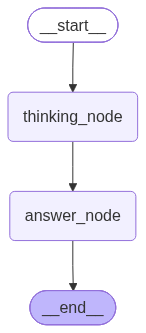

{'answer': 'bye Siva'}

In [48]:
class InputState(TypedDict):
    question: str

class OutputState(TypedDict):
    answer: str

class OverallState(TypedDict):
    question: str
    answer: str
    notes: str

def thinking_node(state: InputState):
    return {"answer": "bye", "notes": "... his is name is siva"}

def answer_node(state: OverallState) -> OutputState:
    return {"answer": "bye Siva"}

graph = StateGraph(OverallState, input=InputState, output=OutputState)
graph.add_node("answer_node", answer_node)
graph.add_node("thinking_node", thinking_node)
graph.add_edge(START, "thinking_node")
graph.add_edge("thinking_node", "answer_node")
graph.add_edge("answer_node", END)

graph = graph.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

graph.invoke({"question": "hi"})